# MARAMA 2026: Ozone and ENSO Analysis

#### Author: Joshua Richards 

Contact: https://www.linkedin.com/in/joshuaadrichards/

### Daily maximum 8-hour ozone (MDA8) -> long-term trends, seasonality, and ENSO differences

**Purpose:** This notebook provides a step-by-step workflow for exploring an ozone dataset, quantifying long-term changes, and comparing monthly ozone behavior across El Niño, La Niña, and Neutral conditions.

### What you will do
1. Load and inspect the ozone dataset.
2. Check data quality and prepare a clean analysis dataframe.
3. Examine the full time series and calculate annual mean ozone trends.
4. Evaluate trends in different parts of the ozone distribution using percentiles.
5. Describe the seasonal ozone cycle.
6. Compare monthly mean ozone among ENSO phases.
7. Calculate ozone differences relative to Neutral conditions.
8. Compare the distributions of ozone concentrations and the fraction above 70 ppbv during selected months.

**How to use this notebook**
- Work from top to bottom the first time. Later sections depend on variables created earlier.
- Run each code cell in order. If you restart the kernel, rerun the notebook from the beginning.
- Read the short notes before each section; they explain the purpose of the analysis and what to look for in the output.
- Change the input file path and analysis choices in the designated cells rather than editing code throughout the notebook.

**Important:** This notebook documents the analysis workflow. Interpretations should be based on the dataset and plots produced when you run it; the workflow itself does not establish that ENSO causes an ozone response.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moroots/marama_2026/blob/main/Session_4_Analysis_Workflows_and_Pipelines/MARAMA_ENSO_Ozone.ipynb)

<div style="border-left:7px solid #f2994a;background:rgba(242,153,74,.15);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    <div style="font-weight:700;font-size:1.08em;margin-bottom:4px">
        ☁️ Using Google Colab? Run the next cell first.
    </div>
    It downloads every course file (they appear under the folder icon on the left) and installs the packages for this notebook. On your own computer, skip it.
</div>

In [ ]:
# Cell 0
# Google Colab only: downloads the course files and installs the tools for this notebook.
# On your own computer this cell does nothing. If Colab asks you to restart the session, restart and run it again.
import sys
if "google.colab" in sys.modules:
    import os, subprocess
    repo = "/content/marama_2026"
    if not os.path.isdir(repo):
        subprocess.run(["git", "clone", "-q", "https://github.com/moroots/marama_2026", repo], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", repo + "[session4]"], check=True)
    sys.path.insert(0, repo + "/src")      # lets this notebook import the course package right away, without a restart
    os.chdir(repo + "/Session_4_Analysis_Workflows_and_Pipelines")
    print("Ready. Click the folder icon on the left to see all the course files.")

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from marama_2026 import sample_datasets as sd    # small real datasets for this course

## 1. Set up: import the libraries

The libraries below provide the main tools used in this analysis:

| Library | Purpose |
|---|---|
| `numpy` | Numerical calculations and arrays |
| `pandas` | Reading, cleaning, grouping, and summarizing the data |
| `matplotlib` | Creating time-series plots and histograms |
| `pathlib` | Defining file paths in a readable, cross-platform way |

**Before running:** Make sure the required packages are installed in the Python environment connected to this notebook. Reading a Parquet file generally requires a Parquet engine such as `pyarrow` or `fastparquet`.

If you are using Anaconda, you can install the common dependencies from an Anaconda Prompt:

```bash
conda install -c conda-forge numpy pandas matplotlib pyarrow scikit-learn
```

*Workflow tip:* In Jupyter, run this cell once after starting or restarting the kernel.

In [3]:
# Load the data file. It downloads from the course GitHub repository the first time, then is read from your computer.
raw_df = sd.load_boulder_ozone()

# Remove unnecessary saved index columns
raw_df = raw_df.drop(
    columns=["Unnamed: 0", "index"],
    errors="ignore"
)

# Convert date/time to datetime format
raw_df["dt"] = pd.to_datetime(raw_df["dt"], errors="coerce")

# Rename the ozone column for easier use
df = raw_df.rename(columns={
    "8_hour_rolling_avg": "ozone_ppbv"
}).copy()

# Create year and month columns
df["Year"] = df["dt"].dt.year
df["Month"] = df["dt"].dt.month

# Standardize ENSO phase labels
df["ENSO_Phase"] = df["ENSO_Phase"].replace({
    "El Niño": "ElNino",
    "La Niña": "LaNina",
    "El Nino": "ElNino",
    "La Nina": "LaNina"
})

# Inspect the prepared dataframe
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())

df.head()

Rows and columns: (11232, 12)
Column names: ['dt', 'Sample Measurement', 'Latitude', 'Longitude', 'ozone_ppbv', 'year_month', 'ENSO_Index', 'ENSO_Phase_Linear', 'detrended', 'Month', 'ENSO_Phase', 'Year']


,dt,Sample Measurement,Latitude,Longitude,ozone_ppbv,year_month,ENSO_Index,ENSO_Phase_Linear,detrended,Month,ENSO_Phase,Year
0,1980-12-03 16:00:00,20.0,40.012969,-105.267212,38.750000,1980-12,-0.3,Neutral,48.315628,12,Neutral,1980
1,1980-12-04 23:00:00,40.0,40.012969,-105.267212,31.250000,1980-12,-0.3,Neutral,40.814861,12,Neutral,1980
2,1980-12-05 06:00:00,40.0,40.012969,-105.267212,39.285714,1980-12,-0.3,Neutral,48.850402,12,Neutral,1980
3,1980-12-09 15:00:00,35.0,40.012969,-105.267212,35.000000,1980-12,-0.3,Neutral,44.562088,12,Neutral,1980
4,1980-12-11 15:00:00,35.0,40.012969,-105.267212,25.666667,1980-12,-0.3,Neutral,35.227566,12,Neutral,1980


## 2. Load the dataset and prepare the time variables

This section reads the Parquet file and prepares the columns used throughout the notebook.

### User adjustment: input file path
The next cell loads `Boulder_8hrOzoneDF.parquet` from the course repository. To analyze your own data, replace that line with `raw_df = pd.read_parquet("path/to/your/file.parquet")`.

### Expected data fields
The workflow expects the dataset to contain:
- `dt`: date/time associated with each ozone observation
- `8_hour_rolling_avg`: daily maximum or selected 8-hour rolling ozone value, renamed here to `ozone_ppbv`
- `ENSO_Phase`: categorical ENSO phase
- `ENSO_Phase_Linear`: ENSO phase label used in the final monthly distribution comparison

The notebook also creates `Year` and `Month` from `dt`.

**Check the printed column names and `df.head()` output.** If a required field is missing or named differently, update the loading/renaming cell before continuing.

In [4]:
df[["ozone_ppbv"]].describe()

,ozone_ppbv
count,11232.000000
mean,45.570286
std,14.983770
min,0.000000
25%,36.000000
50%,45.875000
75%,55.750000
max,102.428571


## 3. Initial data inspection

Use the descriptive statistics to check the ozone variable's sample size, mean, spread, minimum, and maximum.

**Things to check**
- Are the concentration values in the expected units (ppbv)?
- Are the minimum and maximum values physically plausible?
- Does the number of records look reasonable for the period being studied?

These checks do not replace a full quality-control procedure, but they can reveal obvious data or unit problems before analysis.

In [5]:
print("Missing values by column:")
print(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

clean_df = df.dropna(subset=["dt", "ozone_ppbv"]).copy()
print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(clean_df))

Missing values by column:
dt                    0
Sample Measurement    0
Latitude              0
Longitude             0
ozone_ppbv            0
year_month            0
ENSO_Index            0
ENSO_Phase_Linear     0
detrended             0
Month                 0
ENSO_Phase            0
Year                  0
dtype: int64
Duplicate rows: 0
Rows before cleaning: 11232
Rows after cleaning: 11232


## 4. Data quality checks and cleaning

This section reports missing values and duplicate rows, then creates `clean_df` by removing records without a valid date or ozone value.

**Important workflow distinction**
- `df` is the prepared dataframe before this final missing-value filter.
- `clean_df` is the dataframe used for the analyses below.

The cleaning step does not remove every possible questionable observation. Review the missing-value counts and duplicate count, and apply any additional quality-control criteria required by your study before interpreting results.

C:\Users\jrich\AppData\Local\Temp\ipykernel_9324\1469805940.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


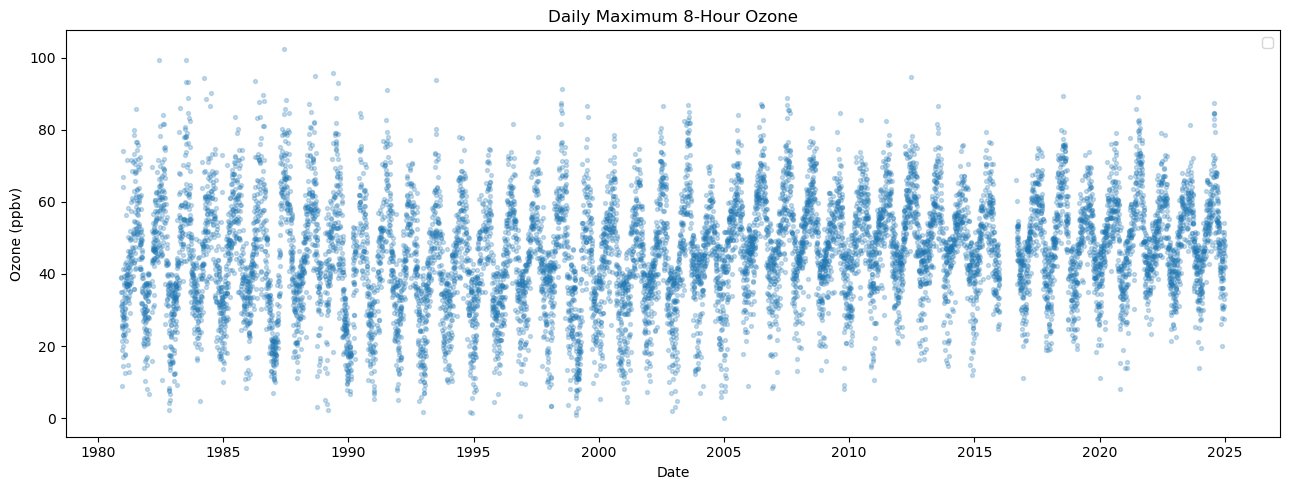

In [6]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.scatter(clean_df["dt"], clean_df["ozone_ppbv"], s=8, alpha=0.25)
ax.set_title("Daily Maximum 8-Hour Ozone")
ax.set_xlabel("Date")
ax.set_ylabel("Ozone (ppbv)")

plt.tight_layout()
plt.legend()
plt.show()

## 5. Explore the full ozone time series

The scatter plot displays individual ozone observations through time.

Use this plot to identify:
- The overall range and variability of ozone.
- Seasonal clustering or recurring high-ozone periods.
- Large gaps in the record.
- Potential changes in the distribution over time.

**Interpretation tip:** A dense cloud of points can make subtle changes difficult to see. The annual summaries and percentile analysis in the next sections help quantify longer-term behavior.

In [7]:
annual_mean = (
    clean_df.groupby("Year")["ozone_ppbv"]
    .mean()
    .reset_index()
)
annual_mean.head()

,Year,ozone_ppbv
0,1980,31.960921
1,1981,41.866985
2,1982,44.360340
3,1983,44.574451
4,1984,44.453948


## 6. Calculate annual mean ozone

The data are grouped by `Year`, and the mean ozone concentration is calculated for each year.

The `head()` and `tail()` outputs provide quick checks of the first and last years in the annual summary.

**Check before proceeding:** Confirm that the annual record covers the period you intend to analyze. Years with incomplete observations may not be directly comparable to years with more complete coverage.

In [8]:
annual_mean.tail()

,Year,ozone_ppbv
40,2020,48.961119
41,2021,51.769582
42,2022,48.941725
43,2023,49.558253
44,2024,50.463598


## 7. Estimate the linear trend in annual mean ozone

A first-order polynomial fit is applied to annual mean ozone as a function of year.

The printed slope is reported in:
- ppbv per year
- ppbv per decade

A positive slope indicates an increase in annual mean ozone over the fitted period; a negative slope indicates a decrease.

**Scientific caution:** This is a simple linear trend. It does not account for autocorrelation, changing emissions, meteorological variability, or other potential drivers. Treat it as a descriptive estimate rather than a complete attribution analysis.

In [9]:
slope, intercept = np.polyfit(
    annual_mean["Year"], annual_mean["ozone_ppbv"], 1
)
annual_mean["trend"] = slope * annual_mean["Year"] + intercept

print(f"Trend: {slope:.3f} ppbv per year")
print(f"Trend: {slope * 10:.2f} ppbv per decade")

Trend: 0.234 ppbv per year
Trend: 2.34 ppbv per decade


## 8. Visualize annual mean ozone and its linear trend

The plot compares the observed annual means with the fitted linear trend.

Look for whether the linear fit represents the overall behavior well or whether the record contains periods of different behavior. A single straight line can summarize the long-term direction while masking nonlinear changes or shorter-term variability.

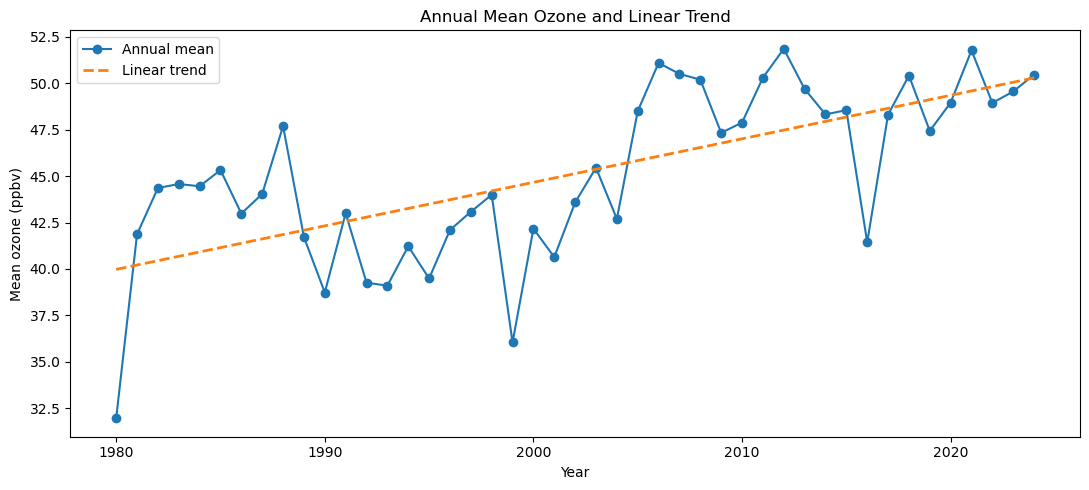

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(annual_mean["Year"], annual_mean["ozone_ppbv"],
        marker="o", label="Annual mean")
ax.plot(annual_mean["Year"], annual_mean["trend"],
        linestyle="--", linewidth=2, label="Linear trend")
ax.set_title("Annual Mean Ozone and Linear Trend")
ax.set_xlabel("Year")
ax.set_ylabel("Mean ozone (ppbv)")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Percentile analysis: are changes similar across the ozone distribution?

The percentile analysis evaluates the 10th, 25th, 75th, and 90th percentiles of annual ozone values. This helps determine whether changes are concentrated in the lower, middle, or upper portions of the ozone distribution.

For example:
- The 10th and 25th percentiles describe the lower part of the distribution.
- The 75th and 90th percentiles describe the upper part of the distribution.
- Comparing their slopes can show whether high-end ozone is changing at a different rate than lower ozone values.

The figure also includes an overall linear fit to the individual observations.

**Interpretation tip:** A rising upper percentile alongside a relatively stable lower percentile would suggest that changes are not uniform across the distribution. The plot alone does not identify the cause of any differences.

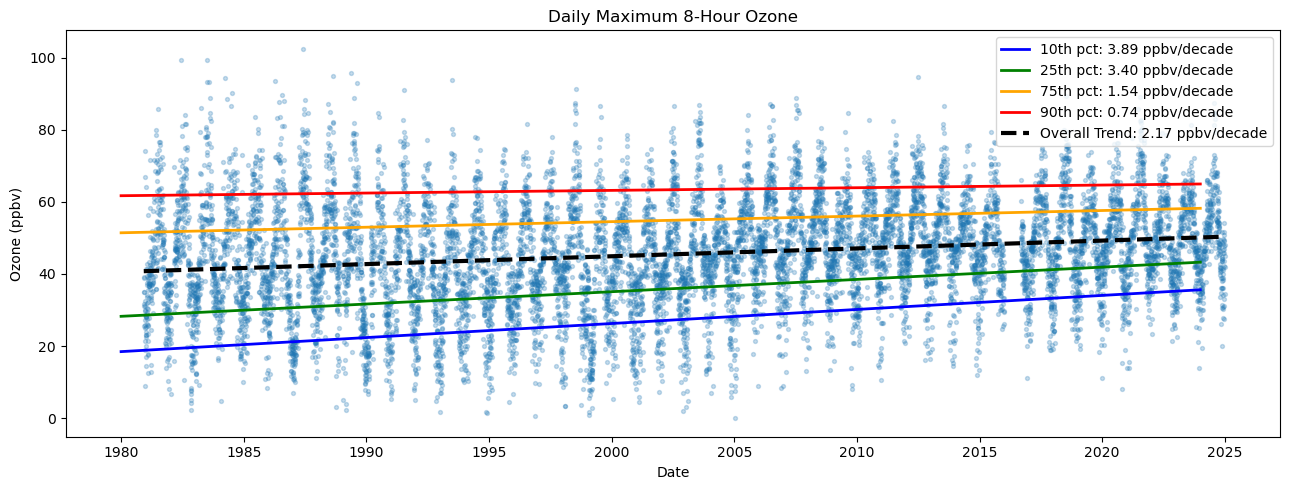

In [11]:
from sklearn.linear_model import LinearRegression


percentiles = [10, 25, 75, 90] # Percentiles of choice

# Creating subsets of data with each percentile  
yearly_percentiles = clean_df.groupby('Year')['ozone_ppbv'].quantile(
        [p/100 for p in percentiles]
    ).unstack()

years = yearly_percentiles.index.values
dates = pd.to_datetime(years, format='%Y')

numdates = np.array([d.timestamp() for d in dates])
baseline = numdates[0]
numdates = (numdates - baseline).reshape(-1,1)

colors = ['blue','green','orange','red']

# Creating your subplot
fig, ax = plt.subplots(figsize=(13, 5))
ax.scatter(clean_df["dt"], clean_df["ozone_ppbv"], s=8, alpha=0.25)

# ---------------------------------------
# Calculating Percentile trend lines
# ---------------------------------------
for i, p in enumerate(percentiles):

    data = yearly_percentiles[p/100].values

    reg = LinearRegression()
    reg.fit(numdates, data)

    y_pred = reg.predict(numdates)

    slope = reg.coef_[0]
    slope_year = slope * 3.15e7

    ax.plot(
        dates,
        y_pred,
        color=colors[i],
        lw=2,
        label=f'{p}th pct: {slope_year*10:.2f} ppbv/decade'
    )

# Overall trend line (original trend)
numdates_all = np.array([d.timestamp() for d in clean_df["dt"]])
baseline_all = numdates_all[0]
numdates_all = (numdates_all - baseline_all).reshape(-1,1)

reg_all = LinearRegression()
reg_all.fit(numdates_all, clean_df["ozone_ppbv"])

y_pred_all = reg_all.predict(numdates_all)

slope_all = reg_all.coef_[0]
slope_all_year = slope_all * 3.15e7

ax.plot(
    clean_df["dt"],
    y_pred_all,
    color='black',
    ls='--',
    lw=3,
    label=f'Overall Trend: {slope_all_year*10:.2f} ppbv/decade'
)

ax.set_title("Daily Maximum 8-Hour Ozone")
ax.set_xlabel("Date")
ax.set_ylabel("Ozone (ppbv)")

plt.tight_layout()
plt.legend()
plt.show()

## 10. Calculate the average seasonal ozone cycle

The observations are grouped by calendar month to calculate the mean ozone concentration for January through December.

This provides a first look at the annual cycle and helps identify the months with typically higher and lower ozone.

**Check:** Confirm that all months have data. If some months are missing or have very few observations, their monthly means may be less representative.

In [12]:
monthly_mean = (clean_df.groupby("Month")["ozone_ppbv"].mean().reindex(range(1, 13)))
monthly_mean

Month
1     33.214596
2     37.481973
3     44.739309
4     51.667077
5     55.626776
6     60.613415
7     62.344164
8     59.009557
9     49.651422
10    37.756194
11    32.891054
12    32.485318
Name: ozone_ppbv, dtype: float64

## 11. Plot mean ozone by month

This plot displays the climatological monthly mean ozone cycle.

Use it to identify the broad seasonal pattern and to decide which months may warrant closer examination. Remember that a monthly mean can hide differences among years and ENSO phases.

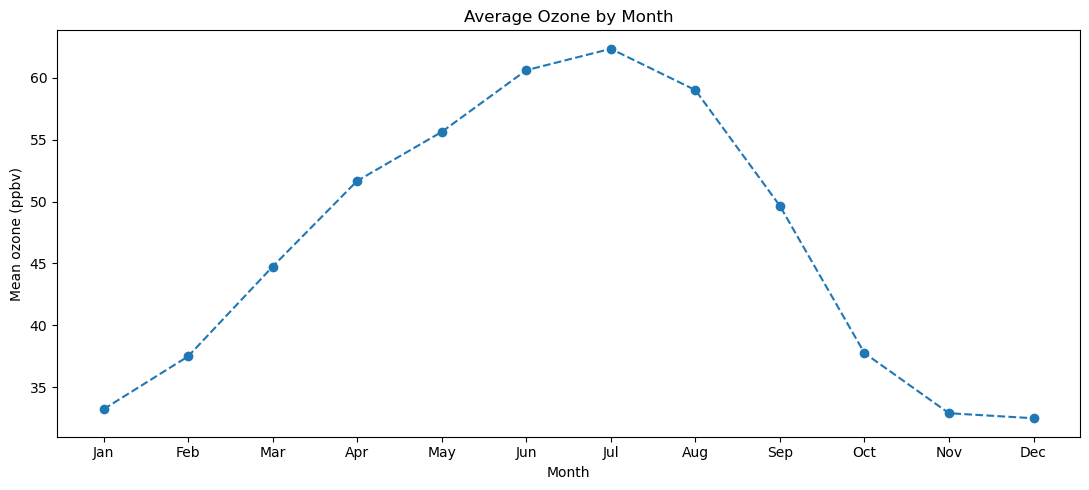

In [13]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(month_names, monthly_mean.values, marker="o", linestyle="--")
ax.set_title("Average Ozone by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Mean ozone (ppbv)")
plt.tight_layout()
plt.show()

## 12. Calculate monthly mean ozone by ENSO phase

The data are grouped by both calendar month and `ENSO_Phase`. The result is reshaped so that each ENSO phase is a separate column.

This makes it possible to compare El Niño, La Niña, and Neutral conditions within the same calendar month, rather than comparing months with different seasonal backgrounds.

**Check the output table:** It should contain the phase columns `ElNino`, `LaNina`, and `Neutral`. If a phase is absent from the dataset or labels are inconsistent, the corresponding column may be missing and later plotting cells may need adjustment.

In [14]:
monthly_by_enso = (
    clean_df.groupby(["Month", "ENSO_Phase"])["ozone_ppbv"]
    .mean()
    .unstack("ENSO_Phase")
    .reindex(range(1, 13))
)
monthly_by_enso

ENSO_Phase,ElNino,LaNina,Neutral
Month,,,
1,30.691329,36.464430,32.051358
2,33.908625,39.468709,37.885627
3,44.077009,44.987005,44.761367
4,52.735258,50.589966,51.687396
5,55.636337,55.146724,55.774230
6,62.936704,59.633371,60.120805
7,60.626622,62.585153,62.738520
8,57.176031,60.742803,59.100977
9,48.370969,52.158246,49.017626


## 13. Set ENSO plotting order and colors

This cell defines a consistent display order and color scheme for the three ENSO phases:

- El Niño: red
- La Niña: blue
- Neutral: gray

Keeping the same colors across figures makes the comparisons easier to follow.

In [15]:
phase_order = ["ElNino", "LaNina", "Neutral"]
phase_colors = {"ElNino": "red", "LaNina": "blue", "Neutral": "gray"}
phase_labels = ["El Niño", "La Niña", "Neutral"]

## 14. Plot monthly mean ozone by ENSO phase

The three lines show how the monthly mean ozone cycle differs among El Niño, La Niña, and Neutral conditions.

**How to read the plot**
- Compare phases within a single month to see the mean difference associated with each phase.
- Compare the shape of the lines to see whether the seasonal cycle differs among phases.
- Look for months where the phase separation is largest or where the ordering changes.

**Caution:** These are unadjusted group means. Differences can also reflect unequal sample sizes, long-term trends, or other meteorological and emissions-related variability.

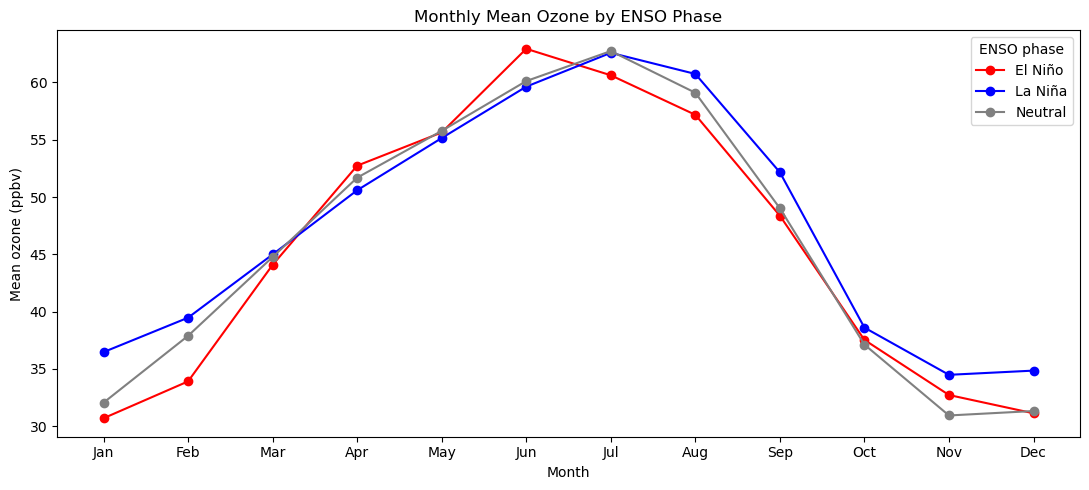

In [16]:
fig, ax = plt.subplots(figsize=(11, 5))

for phase in phase_order:
    label = {"ElNino": "El Niño", "LaNina": "La Niña",
             "Neutral": "Neutral"}[phase]
    ax.plot(month_names, monthly_by_enso[phase],
            marker="o", label=label, color=phase_colors[phase])

ax.set_title("Monthly Mean Ozone by ENSO Phase")
ax.set_xlabel("Month")
ax.set_ylabel("Mean ozone (ppbv)")
ax.legend(title="ENSO phase")
plt.tight_layout()
plt.show()

## 15. Calculate ozone differences relative to Neutral conditions

This section subtracts the Neutral monthly mean from the El Niño and La Niña monthly means.

The resulting values are in ppbv:
- Positive values mean the phase mean is higher than the Neutral mean.
- Negative values mean the phase mean is lower than the Neutral mean.
- Values near zero indicate little difference in the monthly means.

This difference view makes the direction and magnitude of the phase contrasts easier to compare across months.

In [17]:
enso_difference = pd.DataFrame(index=range(1, 13))
enso_difference["ElNino_minus_Neutral"] = (
    monthly_by_enso["ElNino"] - monthly_by_enso["Neutral"]
)
enso_difference["LaNina_minus_Neutral"] = (
    monthly_by_enso["LaNina"] - monthly_by_enso["Neutral"]
)
enso_difference.index.name = "Month"
enso_difference

,ElNino_minus_Neutral,LaNina_minus_Neutral
Month,,
1,-1.360029,4.413071
2,-3.977002,1.583082
3,-0.684358,0.225637
4,1.047862,-1.097430
5,-0.137893,-0.627506
6,2.815899,-0.487434
7,-2.111898,-0.153366
8,-1.924946,1.641826
9,-0.646657,3.140620


## 16. Plot monthly ozone differences from Neutral

The horizontal zero line represents no difference from Neutral conditions.

Use the sign and magnitude of each monthly value to identify when El Niño or La Niña months have higher or lower mean ozone relative to Neutral months.

**Interpretation tip:** Focus on the size and consistency of the differences, not just whether a line is above or below zero. Statistical testing and uncertainty estimates would be needed to determine whether the differences are distinguishable from sampling variability.

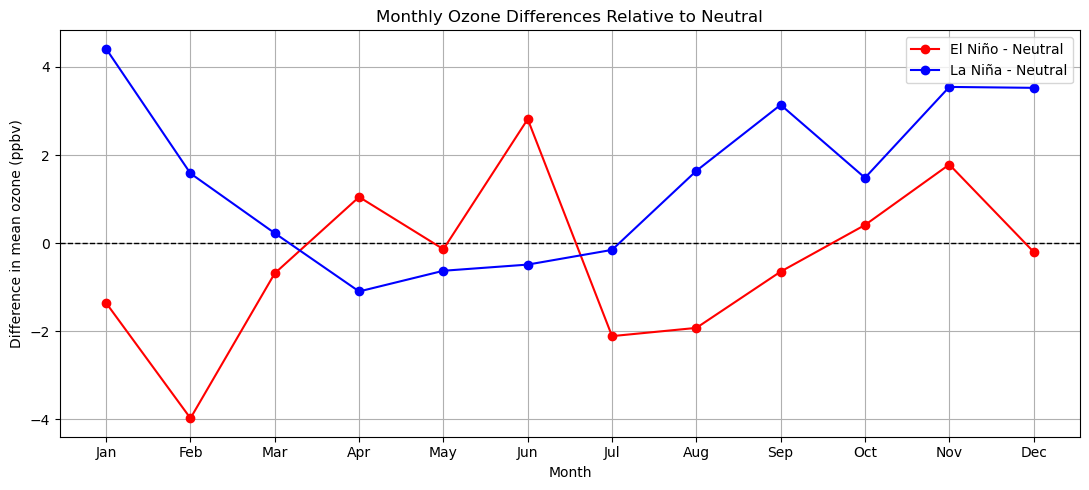

In [18]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.axhline(0, color="black", ls = '--', linewidth=1)

ax.plot(month_names, enso_difference["ElNino_minus_Neutral"],
        marker="o", color="red", label="El Niño - Neutral")
ax.plot(month_names, enso_difference["LaNina_minus_Neutral"],
        marker="o", color="blue", label="La Niña - Neutral")

ax.set_title("Monthly Ozone Differences Relative to Neutral")
ax.set_xlabel("Month")
ax.set_ylabel("Difference in mean ozone (ppbv)")
ax.legend()
ax.grid()
plt.tight_layout()
plt.show()

## 17. Compare ozone distributions and the fraction above 70 ppbv

The final analysis focuses on May, June, July, and August. For each month, it compares the ozone concentration distributions among the three ENSO phases using normalized histograms.

The dashed vertical line marks **70 ppbv**, and the annotation reports the percentage of observations above that threshold for each phase.

### How to interpret the panels
- The histogram shape shows how frequently different ozone concentrations occur within each phase.
- The 70 ppbv line provides a reference for examining the upper end of the distribution.
- The percentage annotation summarizes the fraction of observations above 70 ppbv.

### User adjustments
- Edit `months_tags` to select different months.
- Edit `bins` to change the histogram bin edges.
- Edit the threshold value consistently if your analysis uses a different ozone standard.

**Important methodological note:** The percentages are calculated from the observations included in each month/phase subset. They are not automatically equivalent to the number of regulatory exceedance days unless the input data represent the appropriate daily metric and the exceedance definition matches the regulatory procedure.

The code uses `ENSO_Phase_Linear` for this final comparison, whereas the monthly mean comparison above uses `ENSO_Phase`. Check that these two columns represent the intended and consistent phase classifications before comparing results across sections.

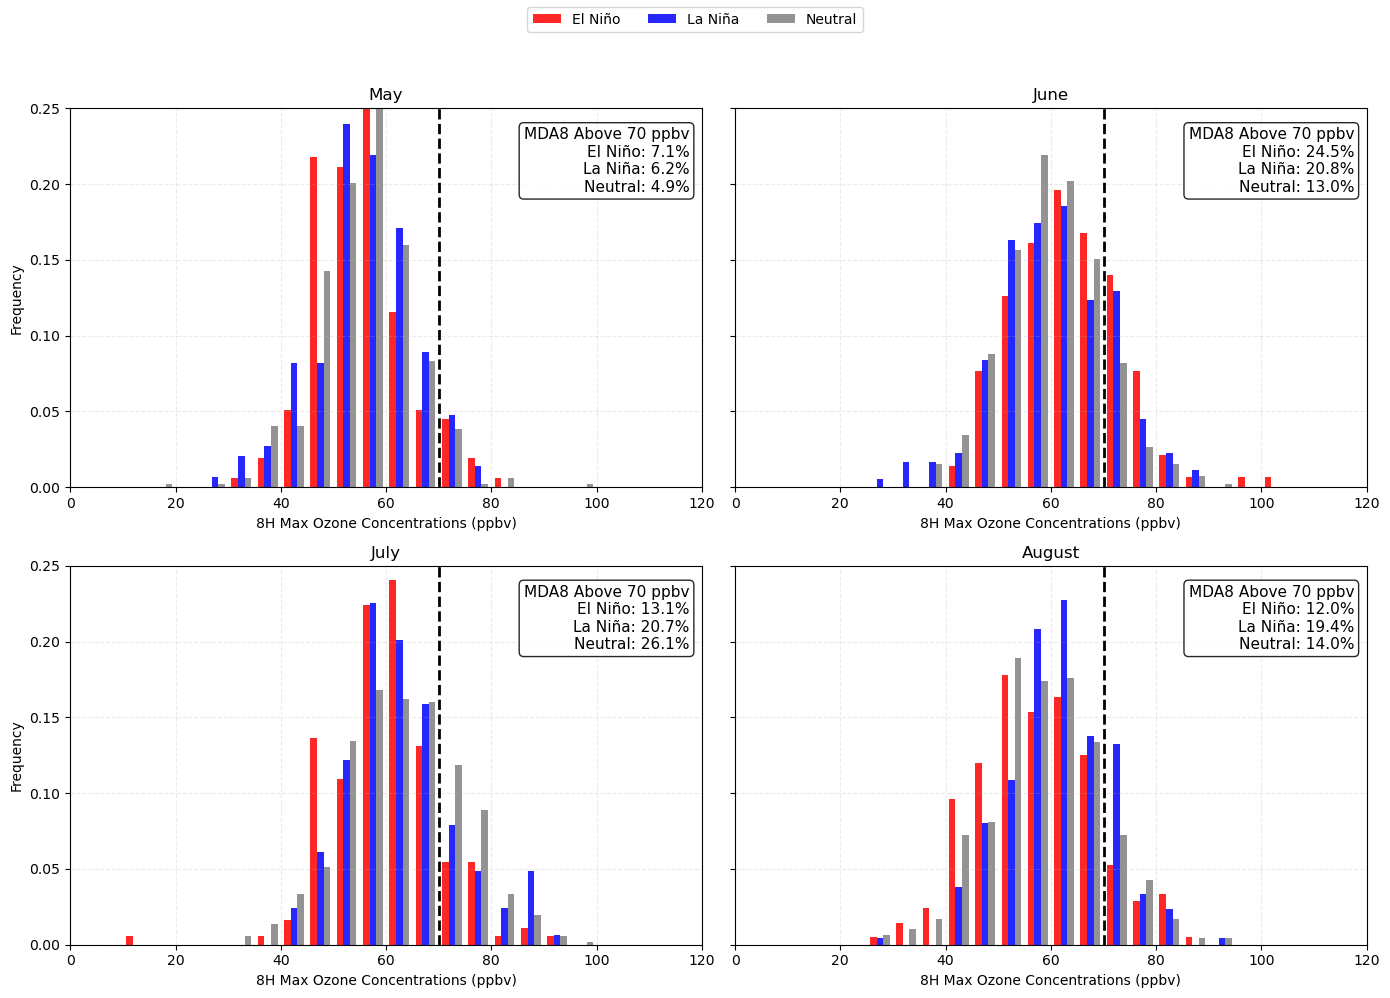

In [19]:
months_tags = [("May",5), ("June",6), ("July",7), ("August",8)]
fig, axes = plt.subplots(2, 2, figsize=(14,10), sharey=True)

bins = np.linspace(0,120,25)
axes = axes.flatten()

for ax, interestmonth in zip(axes, months_tags):

    detrend_vals_el = []
    detrend_vals_la = []
    detrend_vals_ne = []


    monthdf = clean_df[clean_df["Month"] == interestmonth[1]]

    detrend_vals_el = monthdf.loc[monthdf["ENSO_Phase_Linear"]=="ElNino","ozone_ppbv"].values
    detrend_vals_la = monthdf.loc[monthdf["ENSO_Phase_Linear"]=="LaNina","ozone_ppbv"].values
    detrend_vals_ne = monthdf.loc[monthdf["ENSO_Phase_Linear"]=="Neutral","ozone_ppbv"].values

    # -----------------------------------
    # HISTOGRAMS
    # -----------------------------------
    counts1,_ = np.histogram(detrend_vals_el, bins=bins)
    counts2,_ = np.histogram(detrend_vals_la, bins=bins)
    counts3,_ = np.histogram(detrend_vals_ne, bins=bins)

    counts1 = counts1 / counts1.sum()
    counts2 = counts2 / counts2.sum()
    counts3 = counts3 / counts3.sum()

    width = (bins[1]-bins[0]) / 4
    bin_centers = bins[:-1] + (bins[1]-bins[0]) / 2

    #The 3 bars in the histogram
    ax.bar(
        bin_centers-width,
        counts1,
        width=width,
        color="red",
        label="El Niño",
        alpha=0.85
    )

    ax.bar(
        bin_centers,
        counts2,
        width=width,
        color="blue",
        label="La Niña",
        alpha=0.85
    )

    ax.bar(
        bin_centers+width,
        counts3,
        width=width,
        color="gray",
        label="Neutral",
        alpha=0.85
    )

    # 70 ppbv threshold line
    ax.axvline(
        70,
        linestyle="--",
        color="black",
        linewidth=2
    )

    # -----------------------------------
    # PERCENT ABOVE 70
    # -----------------------------------
    def percent_over_70(arr):

        arr = np.array(arr)
        arr = arr[~np.isnan(arr)]

        if len(arr) == 0:
            return np.nan

        return 100 * np.sum(arr > 70) / len(arr)

    p_el = percent_over_70(detrend_vals_el)
    p_la = percent_over_70(detrend_vals_la)
    p_ne = percent_over_70(detrend_vals_ne)

    # -----------------------------------
    # TOP RIGHT TEXT BOX
    # -----------------------------------
    textstr = (
        "MDA8 Above 70 ppbv\n"
        f"El Niño: {p_el:.1f}%\n"
        f"La Niña: {p_la:.1f}%\n"
        f"Neutral: {p_ne:.1f}%"
    )

    ax.text(
        0.98,
        0.95,
        textstr,
        transform=ax.transAxes,
        fontsize=11,
        ha='right',
        va='top',
        bbox=dict(
            boxstyle='round',
            facecolor='white',
            alpha=0.85,
            edgecolor='black'
        )
    )

    
    ax.set_title(interestmonth[0])

    ax.set_xlabel("8H Max Ozone Concentrations (ppbv)")

    ax.set_xlim(0,120)
    ax.set_ylim(0,0.25)

    ax.grid(
        alpha=0.25,
        linestyle='--'
    )

# Shared y label
axes[0].set_ylabel("Frequency")
axes[2].set_ylabel("Frequency")

# -----------------------------------
# SINGLE LEGEND
# -----------------------------------
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    frameon=True
)

plt.tight_layout(rect=[0,0,1,0.93])
plt.show()

<div style="border-left:7px solid #2f80ed;background:rgba(47,128,237,.12);padding:10px 18px;margin:10px 0;border-radius:8px;line-height:1.5">
    <div style="font-weight:700;font-size:1.08em;margin-bottom:4px">
        🎉 That was the last notebook
    </div>
    <a href="https://github.com/moroots/marama_2026" target="_blank">Back to the course page</a>
</div>